# Etapa 3 — análise de sensibilidade da dieta otimizada

Esta etapa mede quanto a solução de menor custo muda quando o preço de cada ingrediente varia. As simulações são enviadas automaticamente para a mesma fila usada nas etapas anteriores.

## 1. Método

Será utilizada uma análise **um fator por vez (OAT)**. Para cada ingrediente, o preço é reduzido em 20% e aumentado em 20%, mantendo os demais parâmetros constantes. Com sete ingredientes, teremos um cenário-base e 14 variações, totalizando 15 otimizações.

Esse método identifica quais preços mais afetam a composição da dieta, o custo alimentar e a margem. Ele não avalia interações simultâneas entre diferentes preços.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rufas_project import (
    DietConfig, DietIngredient, EconomicConfig, HerdConfig, MilkConfig,
    ParityFractions, SimulationConfig, build_composition_matrix,
    generate_price_sensitivity_cases, load_result, submit_simulation,
    summarize_price_sensitivity, validate_simulation_config, wait_for_simulation,
)

SHARED_ROOT = Path(os.getenv('SHARED_ROOT', '/workspace/shared'))
TABLE_STYLES = [
    {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold'), ('text-align', 'left'), ('padding', '8px 0')]},
    {'selector': 'th', 'props': [('background-color', '#256a4b'), ('color', 'white'), ('padding', '8px')]},
    {'selector': 'td', 'props': [('padding', '7px 12px'), ('border-bottom', '1px solid #e5e7eb')]},
]

def show_table(frame, caption, hide_index=True, formatter=None):
    styled = frame.style.set_caption(caption).set_table_styles(TABLE_STYLES)
    if hide_index:
        styled = styled.hide(axis='index')
    if formatter:
        styled = styled.format(formatter)
    display(styled)

## 2. Cenário-base e amplitude das variações

Todos os valores são definidos no notebook. Para alterar a amplitude da análise, modifique `PRICE_MULTIPLIERS`.

In [2]:
PRICE_MULTIPLIERS = (0.80, 1.20)  # -20% e +20%
reference = SimulationConfig(
    name='fase3_referencia', simulation_days=30, random_seed=42,
    herd=HerdConfig(
        cow_num=20, milking_cow_fraction=0.80, breed='HO',
        parity_fractions=ParityFractions(0.40, 0.25, 0.20, 0.10, 0.05),
    ),
    milk=MilkConfig(fat_percent=4.0, protein_percent=3.2, mature_body_weight_kg=740.1),
    diet=DietConfig(
        mode='fixed', formulation_interval_days=30,
        ingredients=[
            DietIngredient(23, 0.74, 0.10, 'Blood meal, low dRUP'),
            DietIngredient(44, 15.31, 0.50, 'Corn grain dry, medium grind'),
            DietIngredient(50, 37.45, 0.01, 'Corn silage, immature'),
            DietIngredient(104, 0.37, 0.01, 'Grass/legume mix, legume silage'),
            DietIngredient(110, 17.65, 0.01, 'Legume silage, mid-maturity'),
            DietIngredient(301, 3.27, 1.00, 'Farm ES Mineral Mix'),
            DietIngredient(302, 25.21, 0.10, 'Farm ES Midwest BP Blend'),
        ],
    ),
    economics=EconomicConfig(
        milk_price_usd_per_kg=0.45,
        milk_price_source='Hipótese didática; substituir por fonte, região e data',
        currency='USD',
    ),
)
names_pt = {
    23: 'Farinha de sangue', 44: 'Milho seco moído', 50: 'Silagem de milho',
    104: 'Mistura gramínea/leguminosa', 110: 'Silagem de leguminosa',
    301: 'Mistura mineral', 302: 'Mistura de subprodutos',
}
parameter_table = pd.DataFrame([
    ('Período da simulação', f'{reference.simulation_days} dias'),
    ('Semente aleatória', reference.random_seed),
    ('Ingredientes avaliados', len(reference.diet.ingredients)),
    ('Variação inferior', f'{PRICE_MULTIPLIERS[0] - 1:+.0%}'),
    ('Variação superior', f'{PRICE_MULTIPLIERS[1] - 1:+.0%}'),
], columns=['Parâmetro', 'Valor'])
show_table(parameter_table, 'Configuração da análise de sensibilidade')

Parâmetro,Valor
Período da simulação,30 dias
Semente aleatória,42
Ingredientes avaliados,7
Variação inferior,-20%
Variação superior,+20%


## 3. Geração sistemática dos cenários

In [3]:
cases = generate_price_sensitivity_cases(reference, PRICE_MULTIPLIERS)
for case in cases:
    validate_simulation_config(case.config)
cases_table = pd.DataFrame([
    {
        'Cenário': case.label,
        'Ingrediente': names_pt.get(case.varied_feed_type, 'Nenhum — cenário-base'),
        'Multiplicador': f'{case.multiplier:.2f}×',
        'Preço original': '—' if case.base_price is None else f'{case.base_price:.3f} USD/kg MS',
        'Preço avaliado': '—' if case.varied_price is None else f'{case.varied_price:.3f} USD/kg MS',
    }
    for case in cases
])
show_table(cases_table, f'{len(cases)} cenários gerados e validados')

Cenário,Ingrediente,Multiplicador,Preço original,Preço avaliado
Cenário-base,Nenhum — cenário-base,1.00×,—,—
Ingrediente 23: 20% menos,Farinha de sangue,0.80×,0.100 USD/kg MS,0.080 USD/kg MS
Ingrediente 23: 20% mais,Farinha de sangue,1.20×,0.100 USD/kg MS,0.120 USD/kg MS
Ingrediente 44: 20% menos,Milho seco moído,0.80×,0.500 USD/kg MS,0.400 USD/kg MS
Ingrediente 44: 20% mais,Milho seco moído,1.20×,0.500 USD/kg MS,0.600 USD/kg MS
Ingrediente 50: 20% menos,Silagem de milho,0.80×,0.010 USD/kg MS,0.008 USD/kg MS
Ingrediente 50: 20% mais,Silagem de milho,1.20×,0.010 USD/kg MS,0.012 USD/kg MS
Ingrediente 104: 20% menos,Mistura gramínea/leguminosa,0.80×,0.010 USD/kg MS,0.008 USD/kg MS
Ingrediente 104: 20% mais,Mistura gramínea/leguminosa,1.20×,0.010 USD/kg MS,0.012 USD/kg MS
Ingrediente 110: 20% menos,Silagem de leguminosa,0.80×,0.010 USD/kg MS,0.008 USD/kg MS


## 4. Execução pela fila

Todas as solicitações são enviadas primeiro. O worker do RuFaS processa uma por vez, preservando isolamento e rastreabilidade.

In [4]:
job_ids = {case.key: submit_simulation(case.config, SHARED_ROOT) for case in cases}
results = {}
for position, case in enumerate(cases, start=1):
    print(f'[{position:02d}/{len(cases)}] {case.label}')
    wait_for_simulation(
        job_ids[case.key], SHARED_ROOT, timeout_seconds=1800, show_progress=False,
    )
    results[case.key] = load_result(job_ids[case.key], SHARED_ROOT)
print('Todas as otimizações foram concluídas com sucesso.')

[01/15] Cenário-base
[02/15] Ingrediente 23: 20% menos
[03/15] Ingrediente 23: 20% mais
[04/15] Ingrediente 44: 20% menos
[05/15] Ingrediente 44: 20% mais
[06/15] Ingrediente 50: 20% menos
[07/15] Ingrediente 50: 20% mais
[08/15] Ingrediente 104: 20% menos
[09/15] Ingrediente 104: 20% mais
[10/15] Ingrediente 110: 20% menos
[11/15] Ingrediente 110: 20% mais
[12/15] Ingrediente 301: 20% menos
[13/15] Ingrediente 301: 20% mais
[14/15] Ingrediente 302: 20% menos
[15/15] Ingrediente 302: 20% mais
Todas as otimizações foram concluídas com sucesso.


## 5. Resultados consolidados

In [5]:
summary = summarize_price_sensitivity(cases, results)
summary['Ingrediente'] = summary['varied_feed_type'].map(names_pt).fillna('Cenário-base')
summary_display = summary.rename(columns={
    'label': 'Cenário',
    'varied_price': 'Preço avaliado (USD/kg MS)',
    'varied_feed_inclusion_pct': 'Inclusão do ingrediente (%)',
    'average_ration_cost_usd_per_cow_day': 'Custo da dieta (USD/vaca/dia)',
    'total_feed_cost_usd': 'Custo alimentar total (USD)',
    'total_feed_cost_usd_change_pct': 'Variação do custo (%)',
    'margin_usd': 'Margem alimentar (USD)',
    'margin_usd_change_pct': 'Variação da margem (%)',
})[[
    'Cenário', 'Ingrediente', 'Preço avaliado (USD/kg MS)',
    'Inclusão do ingrediente (%)', 'Custo da dieta (USD/vaca/dia)',
    'Custo alimentar total (USD)', 'Variação do custo (%)',
    'Margem alimentar (USD)', 'Variação da margem (%)',
]]
show_table(
    summary_display, 'Sensibilidade aos preços dos ingredientes',
    formatter={
        'Preço avaliado (USD/kg MS)': lambda value: '—' if pd.isna(value) else f'{value:.3f}',
        'Inclusão do ingrediente (%)': '{:.2f}',
        'Custo da dieta (USD/vaca/dia)': '{:.3f}',
        'Custo alimentar total (USD)': '{:,.2f}',
        'Variação do custo (%)': '{:+.2f}',
        'Margem alimentar (USD)': '{:,.2f}',
        'Variação da margem (%)': '{:+.2f}',
    },
)

Cenário,Ingrediente,Preço avaliado (USD/kg MS),Inclusão do ingrediente (%),Custo da dieta (USD/vaca/dia),Custo alimentar total (USD),Variação do custo (%),Margem alimentar (USD),Variação da margem (%)
Cenário-base,Cenário-base,—,0.00,0.370,207.53,+0.00,"9,891.44",+0.00
Ingrediente 23: 20% menos,Farinha de sangue,0.080,1.95,0.357,200.55,-3.37,"9,898.43",+0.07
Ingrediente 23: 20% mais,Farinha de sangue,0.120,1.40,0.363,203.67,-1.86,"9,895.31",+0.04
Ingrediente 44: 20% menos,Milho seco moído,0.400,0.00,0.354,198.71,-4.25,"9,900.26",+0.09
Ingrediente 44: 20% mais,Milho seco moído,0.600,0.00,0.354,198.71,-4.25,"9,900.26",+0.09
Ingrediente 50: 20% menos,Silagem de milho,0.008,23.21,0.356,199.60,-3.82,"9,899.37",+0.08
Ingrediente 50: 20% mais,Silagem de milho,0.012,0.00,0.354,198.74,-4.24,"9,900.24",+0.09
Ingrediente 104: 20% menos,Mistura gramínea/leguminosa,0.008,54.77,0.320,179.78,-13.37,"9,919.20",+0.28
Ingrediente 104: 20% mais,Mistura gramínea/leguminosa,0.012,0.00,0.351,197.16,-5.00,"9,901.81",+0.10
Ingrediente 110: 20% menos,Silagem de leguminosa,0.008,98.69,0.289,162.34,-21.78,"9,936.63",+0.46


## 6. Gráfico de impacto sobre a margem

Quanto maior a faixa horizontal, mais sensível é a margem às variações de preço daquele ingrediente.

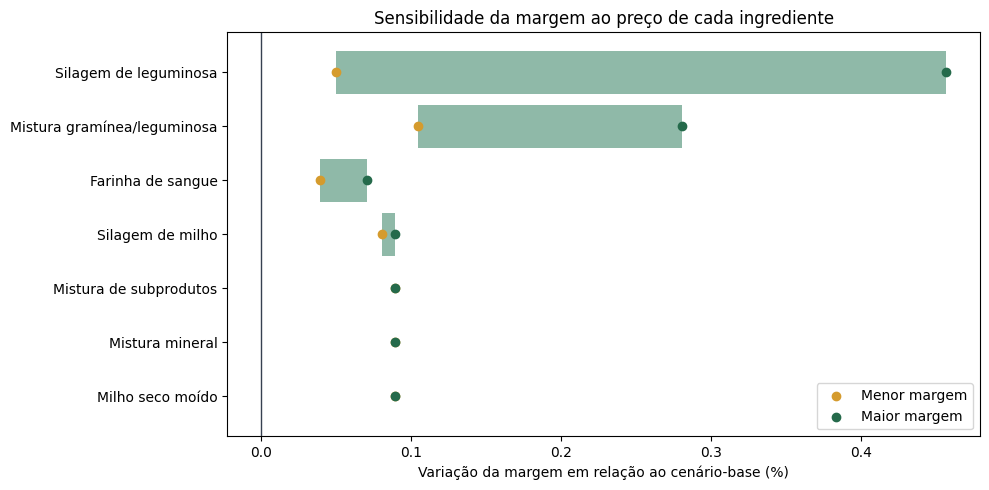

In [7]:
variations = summary[summary['key'] != 'baseline'].copy()
variations['Ingrediente'] = variations['varied_feed_type'].map(names_pt)
impact = (
    variations.groupby('Ingrediente')['margin_usd_change_pct']
    .agg(['min', 'max'])
    .assign(amplitude=lambda frame: frame['max'] - frame['min'])
    .sort_values('amplitude')
)
fig, ax = plt.subplots(figsize=(10, 5))
positions = np.arange(len(impact))
ax.barh(positions, impact['max'] - impact['min'], left=impact['min'], color='#8fb9a8')
ax.scatter(impact['min'], positions, color='#d59b2d', label='Menor margem')
ax.scatter(impact['max'], positions, color='#256a4b', label='Maior margem')
ax.axvline(0, color='#374151', linewidth=1)
ax.set_yticks(positions, impact.index)
ax.set_xlabel('Variação da margem em relação ao cenário-base (%)')
ax.set_title('Sensibilidade da margem ao preço de cada ingrediente')
ax.legend()
plt.tight_layout()

## 7. Mudanças na composição da dieta

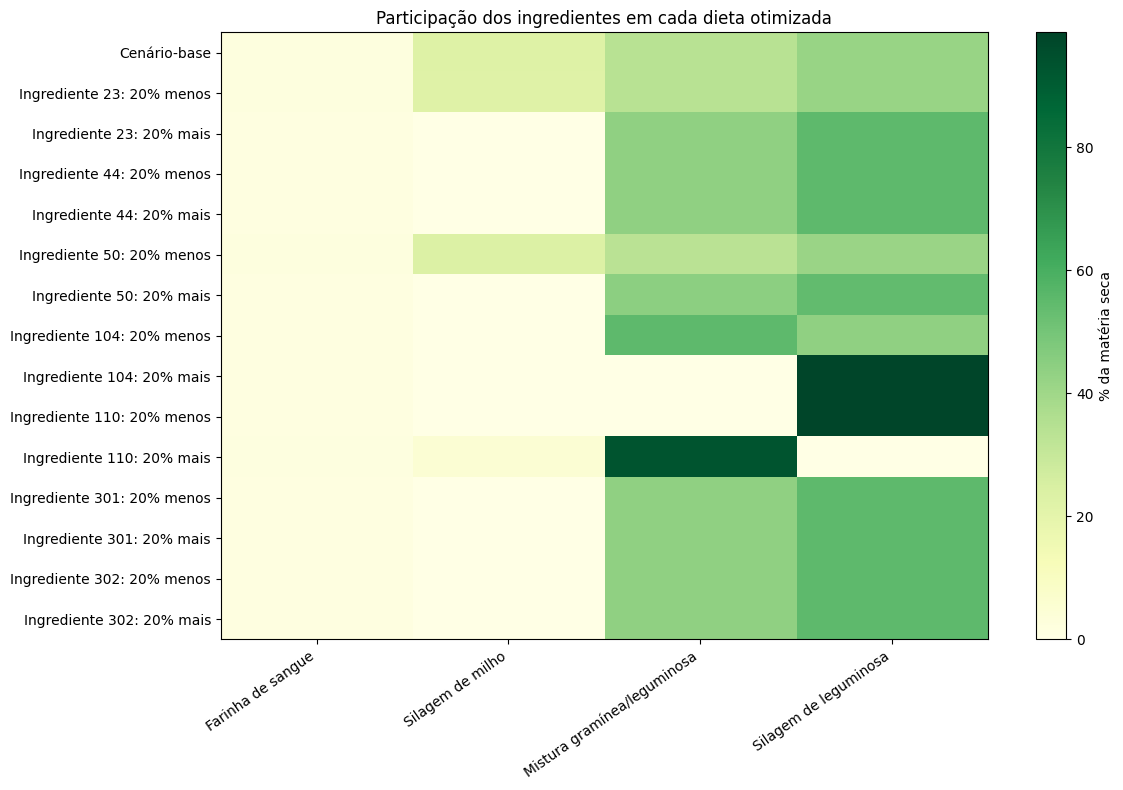

In [8]:
composition = build_composition_matrix(cases, results)
composition_values = composition.drop(columns='label').rename(columns=lambda value: names_pt.get(int(value), value))
fig, ax = plt.subplots(figsize=(12, 8))
image = ax.imshow(composition_values.to_numpy(), aspect='auto', cmap='YlGn', vmin=0)
ax.set_xticks(np.arange(len(composition_values.columns)), composition_values.columns, rotation=35, ha='right')
ax.set_yticks(np.arange(len(composition_values)), composition['label'])
ax.set_title('Participação dos ingredientes em cada dieta otimizada')
colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label('% da matéria seca')
plt.tight_layout()

## 8. Ranking e interpretação

In [9]:
ranking = impact.sort_values('amplitude', ascending=False).reset_index().rename(columns={
    'min': 'Menor variação da margem (%)',
    'max': 'Maior variação da margem (%)',
    'amplitude': 'Amplitude total (p.p.)',
})
show_table(
    ranking, 'Ingredientes ordenados por influência sobre a margem',
    formatter={
        'Menor variação da margem (%)': '{:+.3f}',
        'Maior variação da margem (%)': '{:+.3f}',
        'Amplitude total (p.p.)': '{:.3f}',
    },
)
most_sensitive = ranking.iloc[0]['Ingrediente']
print(f'O ingrediente mais sensível nesta faixa de preços foi: {most_sensitive}.')

Ingrediente,Menor variação da margem (%),Maior variação da margem (%),Amplitude total (p.p.)
Silagem de leguminosa,+0.050,+0.457,0.407
Mistura gramínea/leguminosa,+0.105,+0.281,0.176
Farinha de sangue,+0.039,+0.071,0.032
Silagem de milho,+0.080,+0.089,0.009
Mistura de subprodutos,+0.089,+0.089,0.000
Mistura mineral,+0.089,+0.089,0.000
Milho seco moído,+0.089,+0.089,0.000


O ingrediente mais sensível nesta faixa de preços foi: Silagem de leguminosa.


## 9. Limites da análise

Os resultados valem para a faixa de ±20%, para os preços didáticos informados e para este rebanho. A análise OAT não representa probabilidades nem mede interações entre preços. Antes de uma recomendação real, devem ser usados preços locais, limites de disponibilidade e revisão de um nutricionista. Uma evolução futura pode empregar cenários combinados ou Monte Carlo.